# Practicum 1

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from power_grid_model import (
    AttributeType,
    CalculationMethod,
    CalculationType,
    ComponentType,
    DatasetType,
    LoadGenType,
    PowerGridModel,
    initialize_array,
)
from power_grid_model.validation import assert_valid_input_data

## B1

In [2]:
# node
node = initialize_array(DatasetType.input, ComponentType.node, 3)
node[AttributeType.id] = np.array([1, 2, 6])
node[AttributeType.u_rated] = [10.5e3, 10.5e3, 10.5e3]

# line
line = initialize_array(DatasetType.input, ComponentType.line, 3)
line[AttributeType.id] = [3, 5, 8]
line[AttributeType.from_node] = [1, 2, 1]
line[AttributeType.to_node] = [2, 6, 6]
line[AttributeType.from_status] = [1, 1, 1]
line[AttributeType.to_status] = [1, 1, 1]
line[AttributeType.r1] = [0.25, 0.25, 0.25]
line[AttributeType.x1] = [0.2, 0.2, 0.2]
line[AttributeType.c1] = [10e-6, 10e-6, 10e-6]
line[AttributeType.tan1] = [0.0, 0.0, 0.0]
line[AttributeType.i_n] = [1000, 1000, 1000]

# load
sym_load = initialize_array(DatasetType.input, ComponentType.sym_load, 2)
sym_load[AttributeType.id] = [4, 7]
sym_load[AttributeType.node] = [2, 6]
sym_load[AttributeType.status] = [1, 1]
sym_load[AttributeType.type] = [LoadGenType.const_power, LoadGenType.const_power]
sym_load[AttributeType.p_specified] = [20e6, 10e6]
sym_load[AttributeType.q_specified] = [5e6, 2e6]

# source
source = initialize_array(DatasetType.input, ComponentType.source, 1)
source[AttributeType.id] = [10]
source[AttributeType.node] = [1]
source[AttributeType.status] = [1]
source[AttributeType.u_ref] = [1.0]

# all
input_data = {
    ComponentType.node: node,
    ComponentType.line: line,
    ComponentType.sym_load: sym_load,
    ComponentType.source: source,
}

for component in input_data:
    print(f"------{component}------")
    print(pd.DataFrame(input_data[component]).dropna(axis=1, how="all"))

------node------
   id  u_rated
0   1  10500.0
1   2  10500.0
2   6  10500.0
------line------
   id  from_node  to_node  from_status  to_status    r1   x1       c1  tan1  \
0   3          1        2            1          1  0.25  0.2  0.00001   0.0   
1   5          2        6            1          1  0.25  0.2  0.00001   0.0   
2   8          1        6            1          1  0.25  0.2  0.00001   0.0   

      i_n  
0  1000.0  
1  1000.0  
2  1000.0  
------sym_load------
   id  node  status  type  p_specified  q_specified
0   4     2       1     0   20000000.0    5000000.0
1   7     6       1     0   10000000.0    2000000.0
------source------
   id  node  status  u_ref
0  10     1       1    1.0


## B2

In [3]:
assert_valid_input_data(input_data=input_data, calculation_type=CalculationType.power_flow)
print("Input data is valid")

Input data is valid


## B3

In [4]:
model = PowerGridModel(input_data)

## B4

In [5]:
output_data = model.calculate_power_flow(
    symmetric=True, error_tolerance=1e-8, max_iterations=20, calculation_method=CalculationMethod.newton_raphson
)

## B5

In [6]:
print("------node result------")
print(pd.DataFrame(output_data[ComponentType.node]))
print("------line result------")
print(pd.DataFrame(output_data[ComponentType.line]))

------node result------
   id  energized      u_pu             u   u_angle             p             q
0   1          1  0.998988  10489.375043 -0.003039  3.121451e+07  6.991358e+06
1   2          1  0.952126   9997.325181 -0.026031 -2.000000e+07 -5.000000e+06
2   6          1  0.962096  10102.012975 -0.021895 -1.000000e+07 -2.000000e+06
------line result------
   id  energized   loading        p_from        q_from      i_from  \
0   3          1  0.985666  1.736010e+07  4.072097e+06  981.460041   
1   5          1  0.205940 -3.365614e+06 -1.178649e+06  205.939917   
2   8          1  0.783206  1.385441e+07  2.919262e+06  779.311446   

         s_from          p_to          q_to        i_to          s_to  
0  1.783129e+07 -1.663439e+07 -3.821351e+06  985.666324  1.706768e+07  
1  3.566030e+06  3.396558e+06  8.861080e+05  200.617323  3.510241e+06  
2  1.415863e+07 -1.339656e+07 -2.886108e+06  783.206396  1.370392e+07  


## B6

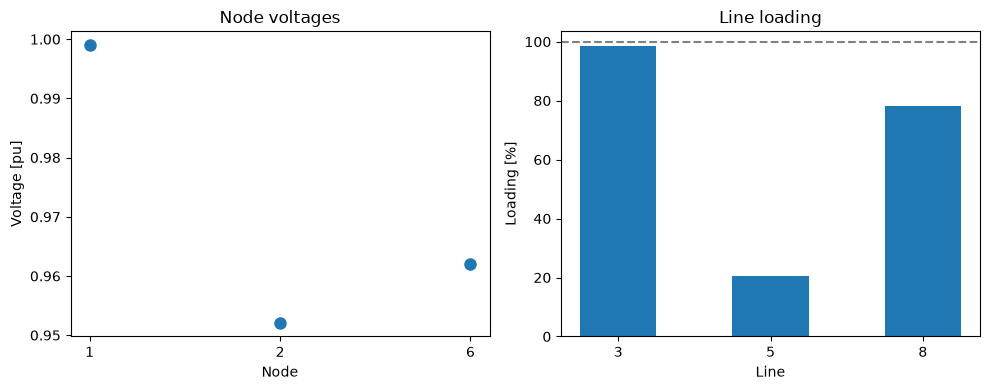

In [7]:
node_result = pd.DataFrame(output_data[ComponentType.node])
line_result = pd.DataFrame(output_data[ComponentType.line])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))
ax1.plot(node_result["id"].astype(str), node_result["u_pu"], "o", markersize=8)
ax1.set_xlabel("Node")
ax1.set_ylabel("Voltage [pu]")
ax1.set_title("Node voltages")
ax2.bar(line_result["id"].astype(str), 100 * line_result["loading"], width=0.5)
ax2.axhline(100, color="grey", linestyle="--")
ax2.set_xlabel("Line")
ax2.set_ylabel("Loading [%]")
ax2.set_title("Line loading")
plt.tight_layout()
plt.show()

## B7

In [8]:
output_data_linear = model.calculate_power_flow(symmetric=True, calculation_method=CalculationMethod.linear)

print("------node result------")
print(pd.DataFrame({
    "id": output_data[ComponentType.node][AttributeType.id],
    "u_pu NR": output_data[ComponentType.node][AttributeType.u_pu],
    "u_pu linear": output_data_linear[ComponentType.node][AttributeType.u_pu],
}))
print("------line result------")
print(pd.DataFrame({
    "id": output_data[ComponentType.line][AttributeType.id],
    "loading NR": output_data[ComponentType.line][AttributeType.loading],
    "loading linear": output_data_linear[ComponentType.line][AttributeType.loading],
}))
print("------sym_load result------")
print(pd.DataFrame({
    "id": output_data[ComponentType.sym_load][AttributeType.id],
    "p NR": output_data[ComponentType.sym_load][AttributeType.p],
    "p linear": output_data_linear[ComponentType.sym_load][AttributeType.p],
}))

------node result------
   id   u_pu NR  u_pu linear
0   1  0.998988     0.999087
1   2  0.952126     0.956325
2   6  0.962096     0.965236
------line result------
   id  loading NR  loading linear
0   3    0.985666        0.900820
1   5    0.205940        0.184308
2   8    0.783206        0.720005
------sym_load result------
   id        p NR      p linear
0   4  20000000.0  1.829115e+07
1   7  10000000.0  9.316798e+06


The linear method treats loads as constant impedance, so it overestimates voltages and underestimates line loading (90.1 % vs 98.6 % on line 3).

## C

In [9]:
topology = pd.read_csv("Practicum_1_Python/grid_topology.csv")
consumption = pd.read_csv("Practicum_1_Python/consumption_one_year_15min.csv", index_col="date")
pv = pd.read_csv("Practicum_1_Python/pv_one_year_15min.csv", index_col="date")
ev = pd.read_csv("Practicum_1_Python/ev_one_year_15min.csv", index_col="date")

# bus number of each customer: "Customer_12 (kW)" -> 12
customers = consumption.columns.str.extract(r"Customer_(\d+)", expand=False).astype(int).to_numpy()

# node (one per customer, same order as the profile columns)
node = initialize_array(DatasetType.input, ComponentType.node, len(customers))
node[AttributeType.id] = customers
node[AttributeType.u_rated] = 400.0

# line
line = initialize_array(DatasetType.input, ComponentType.line, len(topology))
line[AttributeType.id] = 1000 + np.arange(len(topology))
line[AttributeType.from_node] = topology["FROM"]
line[AttributeType.to_node] = topology["TO"]
line[AttributeType.from_status] = 1
line[AttributeType.to_status] = 1
line[AttributeType.r1] = topology["Raa (Ω)"]
line[AttributeType.x1] = topology["Xaa (Ω)"]
line[AttributeType.c1] = 0.0
line[AttributeType.tan1] = 0.0
line[AttributeType.i_n] = topology["Imax"]

# load (one per customer, P and Q are set per time step)
sym_load = initialize_array(DatasetType.input, ComponentType.sym_load, len(customers))
sym_load[AttributeType.id] = 2000 + customers
sym_load[AttributeType.node] = customers
sym_load[AttributeType.status] = 1
sym_load[AttributeType.type] = LoadGenType.const_power
sym_load[AttributeType.p_specified] = 0.0
sym_load[AttributeType.q_specified] = 0.0

# source (MV/LV transformer at bus 1)
source = initialize_array(DatasetType.input, ComponentType.source, 1)
source[AttributeType.id] = [3000]
source[AttributeType.node] = [1]
source[AttributeType.status] = [1]
source[AttributeType.u_ref] = [1.0]

# all
input_data = {
    ComponentType.node: node,
    ComponentType.line: line,
    ComponentType.sym_load: sym_load,
    ComponentType.source: source,
}

assert_valid_input_data(input_data=input_data, calculation_type=CalculationType.power_flow)

In [10]:
def reactive_power(p, power_factor=0.95):
    # leading power factor: Q has the opposite sign of P
    return -p * np.tan(np.arccos(power_factor))


def run_time_series(profile_kw, n_steps=None):
    p = profile_kw.to_numpy()[:n_steps] * 1000  # kW -> W
    q = reactive_power(p)
    names = profile_kw.columns.str.replace(" (kW)", "")

    model = PowerGridModel(input_data)
    update_sym_load = initialize_array(DatasetType.update, ComponentType.sym_load, len(customers))
    update_sym_load[AttributeType.id] = 2000 + customers

    u_pu = np.zeros((len(p), len(customers)))
    loading = np.zeros((len(p), len(topology)))
    for t in range(len(p)):
        update_sym_load[AttributeType.p_specified] = p[t]
        update_sym_load[AttributeType.q_specified] = q[t]
        model.update(update_data={ComponentType.sym_load: update_sym_load})

        output_data = model.calculate_power_flow(
            symmetric=True, error_tolerance=1e-8, max_iterations=20, calculation_method=CalculationMethod.newton_raphson
        )
        u_pu[t] = output_data[ComponentType.node][AttributeType.u_pu]
        loading[t] = output_data[ComponentType.line][AttributeType.loading]
        voltages = {"time step": profile_kw.index[t], "consumers": dict(zip(names, u_pu[t].tolist()))}

    index = profile_kw.index[: len(p)]
    u_pu = pd.DataFrame(u_pu, index=index, columns=names)
    loading = pd.DataFrame(loading, index=index, columns=topology["FROM"].astype(str) + "-" + topology["TO"].astype(str))
    return u_pu, loading, voltages


def summary(u_pu, loading):
    return pd.Series({
        "min voltage [pu]": u_pu.min().min(),
        "max voltage [pu]": u_pu.max().max(),
        "max line loading [%]": 100 * loading.max().max(),
        "lines overloaded at least once": (loading.max() > 1).sum(),
        "hours with an overloaded line": 0.25 * (loading.max(axis=1) > 1).sum(),
    })

In [11]:
u_test, loading_test, voltages = run_time_series(consumption, n_steps=4)
print(voltages)

{'time step': '2020-01-01 00:45:00', 'consumers': {'Customer_1': 1.000000311123687, 'Customer_2': 0.9997311054038558, 'Customer_3': 0.9997374965314978, 'Customer_4': 0.9997031336930853, 'Customer_5': 0.9996816875399556, 'Customer_6': 0.9996114374098952, 'Customer_7': 0.9996655957157665, 'Customer_8': 0.9996502022058561, 'Customer_9': 0.9996390120858417, 'Customer_10': 0.9997311054038558, 'Customer_11': 0.9996353655721585, 'Customer_12': 0.9996027511966391, 'Customer_13': 0.9996203414492579, 'Customer_14': 0.9994167077096432, 'Customer_15': 0.9996062500877115, 'Customer_16': 0.9995925108755823, 'Customer_17': 0.9993841393825512, 'Customer_18': 0.999602751196639, 'Customer_19': 0.9993496946602465, 'Customer_20': 0.9993681920347803, 'Customer_21': 0.9995701192704024, 'Customer_22': 0.9993524905268495, 'Customer_23': 0.9995605930738044, 'Customer_24': 0.9993379048707074, 'Customer_25': 0.9995009799026369, 'Customer_26': 0.9993262582089248, 'Customer_27': 0.9995410528098244, 'Customer_28': 

In [12]:
u_base, loading_base, voltages = run_time_series(consumption)
print(voltages)
print(summary(u_base, loading_base))

{'time step': '2020-12-31 23:45:00', 'consumers': {'Customer_1': 1.0000004071140767, 'Customer_2': 0.9997124005100061, 'Customer_3': 0.9996549182783901, 'Customer_4': 0.9995990644786512, 'Customer_5': 0.999567896516864, 'Customer_6': 0.9995921682874205, 'Customer_7': 0.999542955522049, 'Customer_8': 0.9995169347813427, 'Customer_9': 0.999498812453157, 'Customer_10': 0.9997124005100061, 'Customer_11': 0.9994929069654604, 'Customer_12': 0.9995871161711666, 'Customer_13': 0.9994691289457339, 'Customer_14': 0.9993917288463484, 'Customer_15': 0.9994481036816079, 'Customer_16': 0.9994295676755768, 'Customer_17': 0.9993498813011092, 'Customer_18': 0.999583741998816, 'Customer_19': 0.999335445571574, 'Customer_20': 0.999330600472177, 'Customer_21': 0.9993977537152615, 'Customer_22': 0.9993117955399504, 'Customer_23': 0.9993838360648468, 'Customer_24': 0.9992943270438259, 'Customer_25': 0.9994149707063498, 'Customer_26': 0.9992788423953046, 'Customer_27': 0.9993552881181219, 'Customer_28': 0.99

## D

In [13]:
from pathlib import Path

combined = consumption + ev - pv

# saved next to this notebook (Jupyter runs from the notebook's own folder)
net_load_file = Path("net_load_pv_ev_one_year_15min.csv")
if net_load_file.exists():
    print(f"{net_load_file} exists, filling it with the new net load")
else:
    print(f"{net_load_file} does not exist yet, creating it")
combined.to_csv(net_load_file, float_format="%.6f")

u_pv_ev, loading_pv_ev, voltages = run_time_series(combined)
print(summary(u_pv_ev, loading_pv_ev))

net_load_pv_ev_one_year_15min.csv does not exist yet, creating it
min voltage [pu]                     0.984501
max voltage [pu]                     1.077698
max line loading [%]               371.929262
lines overloaded at least once      33.000000
hours with an overloaded line     1335.000000
dtype: float64


In [14]:
# voltage magnitudes with and without PV/EV
total = combined.sum(axis=1)
shown = ["Customer_1", "Customer_20", "Customer_66", "Customer_91", "Customer_95"]
for t in [total.idxmin(), total.idxmax()]:  # largest PV export, largest demand
    print(f"------{t}, total net load {total[t]:.0f} kW------")
    print(pd.DataFrame({"without PV/EV": u_base.loc[t, shown], "with PV/EV": u_pv_ev.loc[t, shown]}))

------2020-05-18 11:30:00, total net load -1140 kW------
             without PV/EV  with PV/EV
Customer_1        1.000001    0.999971
Customer_20       0.998926    1.050552
Customer_66       0.999215    1.045862
Customer_91       0.998375    1.075202
Customer_95       0.998520    1.077698
------2020-03-19 18:30:00, total net load 134 kW------
             without PV/EV  with PV/EV
Customer_1        1.000001    1.000003
Customer_20       0.997421    0.995111
Customer_66       0.998042    0.991889
Customer_91       0.996363    0.994471
Customer_95       0.996147    0.990218


In [15]:
# line loadings with and without PV/EV (10 most loaded lines)
print(pd.DataFrame({
    "max loading without PV/EV": loading_base.max(),
    "max loading with PV/EV": loading_pv_ev.max(),
}).sort_values("max loading with PV/EV", ascending=False).head(10))
print("Highest loading at:", loading_pv_ev.max(axis=1).idxmax())

       max loading without PV/EV  max loading with PV/EV
2-1                     0.273072                3.719293
6-2                     0.258449                3.569674
6-14                    0.230507                3.349288
1-3                     0.247815                3.067705
3-4                     0.138412                1.839189
4-5                     0.130726                1.763559
14-19                   0.124306                1.708394
5-7                     0.130213                1.691981
19-30                   0.122401                1.636159
7-8                     0.123491                1.620775
Highest loading at: 2020-05-18 11:30:00


In [16]:
# flexible setup: 1 = customer owns PV / EV charger, 0 = not
has_pv = pd.Series(1, index=consumption.columns)
has_ev = pd.Series(1, index=consumption.columns)
has_ev[["Customer_10 (kW)", "Customer_20 (kW)"]] = 0  # PV but no EV charger at buses 10 and 20

flexible = consumption + ev * has_ev - pv * has_pv
u_flex, loading_flex, _ = run_time_series(flexible)
print(summary(u_flex, loading_flex))

min voltage [pu]                     0.984501
max voltage [pu]                     1.077698
max line loading [%]               371.929262
lines overloaded at least once      33.000000
hours with an overloaded line     1335.250000
dtype: float64


## Discussion

**Impact on voltage.** Without PV/EV, the voltages stay between 0.994 and 1.000 pu. With uncontrolled PV/EV they vary between 0.985 and 1.078 pu, which is still inside the 0.90–1.10 pu limits.

**Impact on line loading.** The highest line loading goes from 27 % without PV/EV to 372 % with PV/EV, on line 2-1 at the transformer. 33 lines are overloaded at some point, so the main problem is congestion.

**Same or different effects? Different.** PV raises the voltage at midday because power flows back to the transformer. EV charging lowers it in the evening. Both increase line loading, but the overloads come from PV: the highest loading occurs at the moment of largest PV export, because all PV systems produce at the same time.

**Flexible setup.** Give each customer an ownership flag `has_pv` / `has_ev` (1 or 0) and use net load = consumption + has_ev · EV − has_pv · PV. For the example, set `has_ev = 0` for the customers at buses 10 and 20.